<a href="https://colab.research.google.com/github/tlh222k/aio/blob/main/M4/foundational-deep-learning/05-pytorch-framework/code/softmax/softmax-PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [51]:
!curl -L -o iris_2D_3c.csv https://raw.githubusercontent.com/tlh222k/aio/refs/heads/main/data/iris_2D_3c.csv

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   141  100   141    0     0   1483      0 --:--:-- --:--:-- --:--:--  1500


In [52]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# Load Data

In [53]:
iris = np.genfromtxt("/content/iris_2D_3c.csv" ,
                     dtype=None,
                     delimiter=",",
                     skip_header=True)
X = torch.tensor(iris[:,:2], dtype = torch.float32)
y = torch.tensor(iris[:,-1], dtype = torch.long)

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

X shape: torch.Size([9, 2])
y shape: torch.Size([9])


# Define the model

In [54]:
!pip install -q torchinfo
from torchinfo import summary

input_dim = X.shape[1]
oput_dim = len(y.unique())

# Định nghĩa mô hình Sequential trực tiếp
model = nn.Sequential(
    nn.Linear(input_dim, oput_dim)
)

# Truy cập đúng layer tuyến tính đầu tiên trong model để in trọng số ban đầu
initial_layer = model[0]
print(f"weight: {initial_layer.weight}")
print(f"bias: {initial_layer.bias}")
print(50*"-")
summary(model, input_size=(1, input_dim))

weight: Parameter containing:
tensor([[ 0.6298,  0.6261],
        [ 0.1695, -0.2631],
        [-0.4228,  0.0239]], requires_grad=True)
bias: Parameter containing:
tensor([ 0.4052, -0.0551, -0.2400], requires_grad=True)
--------------------------------------------------


Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 3]                    --
├─Linear: 1-1                            [1, 3]                    9
Total params: 9
Trainable params: 9
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00

# Loss and optimizer

In [55]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.1)

# Training loop

In [56]:
max_epoch = 5000
losses = []

for epoch in range(max_epoch):
    # Forward pass
    outputs = model(X)

    # Compute loss
    loss = criterion(outputs, y)
    losses.append(loss.item())

    # Backward pass and optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

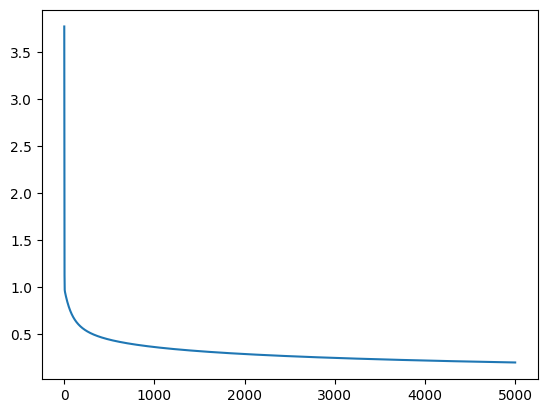

In [57]:
import matplotlib.pyplot as plt

plt.plot(losses)

In [58]:
# Compute accuracy for data X
with torch.no_grad():
    outputs = model(X)
    predicted = torch.argmax(outputs, 1)
    accuracy = (predicted == y).sum().item() / y.size(0)
    print(f'Accuracy: {accuracy * 100:.2f}%')

Accuracy: 100.00%
